# EN3160 Assignment 2

### A.H.T.M. Weerakoon



### 230689A

In [2]:
import os, glob
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.optimize import minimize
%matplotlib inline

def show(img_bgr, title='', figsize=(10, 7)):
    plt.figure(figsize=figsize)
    if img_bgr.ndim == 2:
        plt.imshow(img_bgr, cmap='gray')
    else:
        plt.imshow(cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis('off'); plt.show()

### Question 01

Image size: (360, 360, 3)
sigma range used: 1.0 to 20.0 (40 scales, geometric spacing)
Number of circles detected: 2473


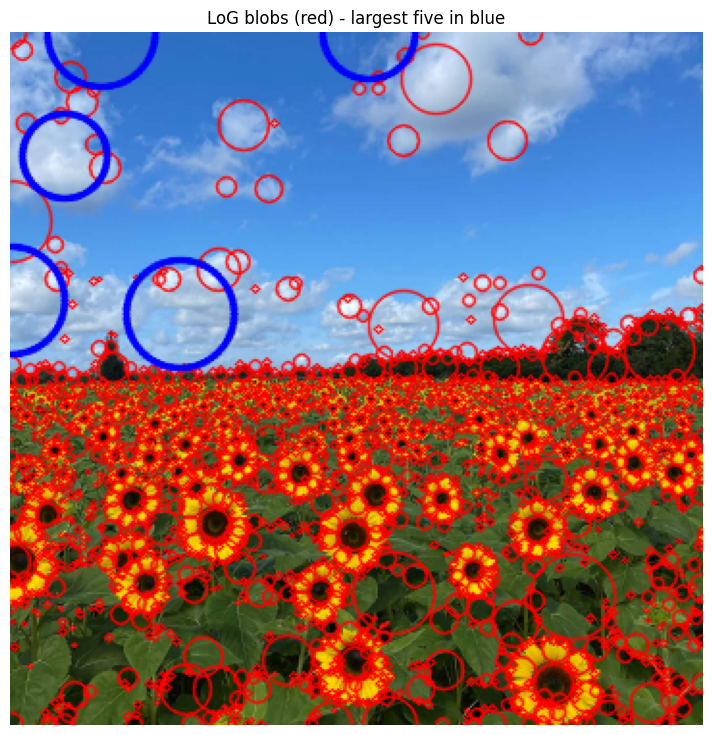

 #      x      y   sigma  radius  |response|
 1     47      0   20.00   28.28       0.101
 2     88    146   20.00   28.28       0.118
 3      0    139   20.00   28.28       0.120
 4    186      0   17.15   24.26       0.102
 5     28     64   15.88   22.46       0.146


In [3]:
im = cv.imread('images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, 'Check the image path'
gray = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float64) / 255.0
print('Image size:', im.shape)

def log_scale_space(img, sigmas):
    # Scale-normalised LoG stack, shape (S, H, W)
    return np.stack([s**2 * ndimage.gaussian_laplace(img, sigma=s) for s in sigmas], axis=0)

def detect_blobs(img, sigmas, threshold=0.08, overlap=0.5):
    L = np.abs(log_scale_space(img, sigmas))
    # Scale-space extrema: equal to the max of its 3x3x3 neighbourhood and above threshold
    peaks = (L == ndimage.maximum_filter(L, size=(3, 3, 3))) & (L > threshold)
    s_idx, ys, xs = np.nonzero(peaks)
    resp = L[s_idx, ys, xs]
    sig = sigmas[s_idx]
    rad = np.sqrt(2) * sig

    # Greedy non-maximum suppression of overlapping circles (strongest first)
    keep = []
    for i in np.argsort(-resp):
        if keep:
            k = np.array(keep)
            dist = np.hypot(xs[k] - xs[i], ys[k] - ys[i])
            if np.any(dist < overlap * (rad[k] + rad[i])):
                continue
        keep.append(i)
    keep = np.array(keep, dtype=int)
    return xs[keep], ys[keep], rad[keep], sig[keep], resp[keep]


sigma_min, sigma_max, n_scales = 1.0, 20.0, 40      # tune if needed
sigmas = np.geomspace(sigma_min, sigma_max, n_scales)
threshold = 0.08                                     # raise -> fewer, stronger blobs

xs, ys, rad, sig, resp = detect_blobs(gray, sigmas, threshold=threshold)
print(f'sigma range used: {sigma_min} to {sigma_max} ({n_scales} scales, geometric spacing)')
print('Number of circles detected:', len(rad))

out = im.copy()
for x, y, r in zip(xs, ys, rad):
    cv.circle(out, (int(x), int(y)), int(round(r)), (0, 0, 255), 1, cv.LINE_AA)

# Highlight the largest circles
order = np.argsort(-rad)
for i in order[:5]:
    cv.circle(out, (int(xs[i]), int(ys[i])), int(round(rad[i])), (255, 0, 0), 2, cv.LINE_AA)
show(out, 'LoG blobs (red) - largest five in blue', figsize=(12, 9))

print(f"{'#':>2} {'x':>6} {'y':>6} {'sigma':>7} {'radius':>7} {'|response|':>11}")
for k, i in enumerate(order[:5], 1):
    print(f'{k:>2} {xs[i]:>6} {ys[i]:>6} {sig[i]:>7.2f} {rad[i]:>7.2f} {resp[i]:>11.3f}')

σ ranges from 1 to 20 over 40 geometrically spaced scales, with threshold 0.08 on $|\sigma^2\nabla^2 G|$. The largest circles are listed in the printed table: centre, σ and radius ($r = \sqrt{2}\,\sigma$).

- **Why scale-normalise.** The raw LoG response shrinks as σ grows. Multiplying by $\sigma^2$ makes responses comparable across scales, so a blob peaks at the σ that matches its size.
- **Why $r = \sqrt{2}\,\sigma$.** The normalised LoG response of a disc of radius $r$ is maximal at $\sigma = r/\sqrt{2}$.
- **What gets detected.** Large, near flower heads give the largest circles; distant flowers are found at small σ. Using $|\text{LoG}|$ catches both dark flower centres and bright yellow heads.
- **Tuning.** If the largest circles sit at σ = 20, extend the range, because a peak on the last scale is not a true extremum. Raising the threshold removes false blobs on leaves and sky but also misses small, far flowers.

### Question 02

In [4]:
# Generation of a noisy point set conforming to a line and a circle (given code)
np.random.seed(0)          # fixed for reproducibility of the report
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2*np.pi, half_n)
n = s*np.random.randn(half_n)
x, y = x0_gt + (r + n)*np.cos(t), y0_gt + (r + n)*np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m*x + b + s*np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

def n_iterations(p, e, s):
    return int(np.ceil(np.log(1 - p) / np.log(1 - (1 - e)**s)))
print('Required iterations  line:', n_iterations(0.99, 0.5, 2), ' circle:', n_iterations(0.99, 0.5, 3))

Required iterations  line: 17  circle: 35


In [5]:
# ---------- Line model ----------
def line_from_points(p1, p2):
    d = p2 - p1
    nrm = np.hypot(d[0], d[1])
    if nrm < 1e-12:
        return None
    a, b = -d[1] / nrm, d[0] / nrm           # unit normal
    return np.array([a, b, a*p1[0] + b*p1[1]])

def line_error(model, P):
    a, b, d = model
    return np.abs(a*P[:, 0] + b*P[:, 1] - d)

def fit_line(P, x0):
    # Total least squares with the constraint a^2 + b^2 = 1
    obj = lambda q: np.sum((q[0]*P[:, 0] + q[1]*P[:, 1] - q[2])**2)
    con = {'type': 'eq', 'fun': lambda q: q[0]**2 + q[1]**2 - 1}
    res = minimize(obj, x0, method='SLSQP', constraints=con)
    q = res.x / np.hypot(res.x[0], res.x[1])
    return q

# ---------- Circle model ----------
def circle_from_points(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    if abs(np.linalg.det(A)) < 1e-9:          # collinear sample
        return None
    c = np.linalg.solve(A, rhs)
    return np.array([c[0], c[1], np.linalg.norm(p1 - c)])

def circle_error(model, P):
    xc, yc, rc = model
    return np.abs(np.hypot(P[:, 0] - xc, P[:, 1] - yc) - rc)

def fit_circle(P, x0):
    obj = lambda q: np.sum((np.hypot(P[:, 0] - q[0], P[:, 1] - q[1]) - q[2])**2)
    return minimize(obj, x0, method='BFGS').x

# ---------- Generic RANSAC ----------
def ransac(P, s, model_from_sample, error_fn, fit_fn, t, min_inliers, n_iter=1000, seed=1):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_iter):
        idx = rng.choice(len(P), s, replace=False)
        model = model_from_sample(*P[idx])
        if model is None:
            continue
        err = error_fn(model, P)
        inl = np.flatnonzero(err < t)
        if len(inl) < min_inliers:              # consensus not reached
            continue
        score = (len(inl), -err[inl].mean())    # more inliers, then lower error
        if best is None or score > best['score']:
            best = dict(score=score, sample=idx, sample_model=model, inliers=inl)
    if best is None:
        raise RuntimeError('No model reached the required consensus')
    best['model'] = fit_fn(P[best['inliers']], best['sample_model'])   # refit on all inliers
    best['inliers'] = np.flatnonzero(error_fn(best['model'], P) < t)
    return best

In [6]:
# (a) Line first
t_line, min_line = 1.0, 35        # noise sigma along normal = 1/sqrt(2) ~ 0.71
line = ransac(X, 2, line_from_points, line_error, fit_line, t_line, min_line)
print('Line  [a, b, d] =', np.round(line['model'], 4), ' inliers:', len(line['inliers']))

# (b) Remove line consensus, fit circle to the remnant
mask = np.ones(len(X), bool); mask[line['inliers']] = False
X_rem = X[mask]
t_circ, min_circ = 1.25, 30       # radial noise sigma = r/16 = 0.625 -> t = 2 sigma
circ = ransac(X_rem, 3, circle_from_points, circle_error, fit_circle, t_circ, min_circ)
print('Circle [xc, yc, r] =', np.round(circ['model'], 4), ' inliers:', len(circ['inliers']))

Line  [a, b, d] = [0.7257 0.688  1.6319]  inliers: 48
Circle [xc, yc, r] = [1.9496 2.9954 9.8945]  inliers: 49


**Choice of thresholds and consensus.** Each threshold is set from the noise in the data generator, and each consensus is a bit below the expected number of true inliers (50 points per model).

| Model | Error used | Noise σ | Threshold t | Min. consensus | Result (seed 0) |
| --- | --- | --- | --- | --- | --- |
| Line | Normal distance $\lvert ax + by - d\rvert$ | $1/\sqrt{2} \approx 0.71$ | 1.0 | 35 | [0.726, 0.688, 1.632], 48 inliers |
| Circle | Radial distance $\lvert\,\lVert \mathbf{x} - \mathbf{c}\rVert - r\,\rvert$ | $r/16 = 0.625$ | 1.25 (2σ) | 30 | (1.95, 3.00, 9.89), 49 inliers |

The line noise is 1.0 in y; for a slope of −1 the normal component is $1/\sqrt{2}$ of that. A tighter threshold keeps circle points that cross the line from joining the line consensus. Ground truth is [0.707, 0.707, 1.414] for the line and (2, 3, 10) for the circle, so both fits are close. The best sample is the one with the most inliers (ties broken by lower mean error); the model is then refitted on all its inliers with `scipy.optimize.minimize`, using SLSQP to keep $a^2 + b^2 = 1$ for the line.

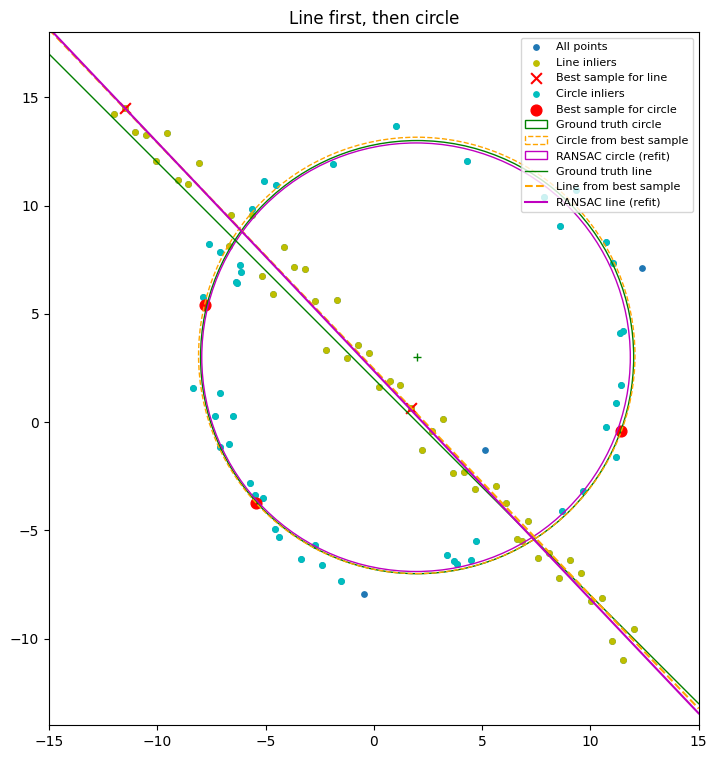

In [7]:
def plot_line(ax, model, xlim, **kw):
    a, b, d = model
    xx = np.array(xlim)
    if abs(b) > 1e-9:
        ax.plot(xx, (d - a*xx) / b, **kw)
    else:
        ax.axvline(d / a, **kw)

def plot_result(X, line, circ, X_rem, title):
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.scatter(X[:, 0], X[:, 1], s=15, color='tab:blue', label='All points')
    ax.scatter(X[line['inliers'], 0], X[line['inliers'], 1], s=15, color='y', label='Line inliers')
    ax.scatter(X[line['sample'], 0], X[line['sample'], 1], marker='x', s=60, color='r', label='Best sample for line')
    ax.scatter(X_rem[circ['inliers'], 0], X_rem[circ['inliers'], 1], s=15, color='c', label='Circle inliers')
    ax.scatter(X_rem[circ['sample'], 0], X_rem[circ['sample'], 1], s=60, color='r', label='Best sample for circle')

    ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
    ax.add_patch(plt.Circle(circ['sample_model'][:2], circ['sample_model'][2], color='orange', ls='--',
                            fill=False, label='Circle from best sample'))
    ax.add_patch(plt.Circle(circ['model'][:2], circ['model'][2], color='m', fill=False, label='RANSAC circle (refit)'))
    ax.plot(x0_gt, y0_gt, '+', color='g')

    xlim = (-15, 15)
    ax.plot(xlim, m*np.array(xlim) + b, color='g', lw=1, label='Ground truth line')
    plot_line(ax, line['sample_model'], xlim, color='orange', ls='--', label='Line from best sample')
    plot_line(ax, line['model'], xlim, color='m', label='RANSAC line (refit)')
    ax.set_xlim(xlim); ax.set_ylim(-14, 18); ax.set_aspect('equal')
    ax.legend(loc='upper right', fontsize=8); ax.set_title(title); plt.show()

plot_result(X, line, circ, X_rem, 'Line first, then circle')

Circle first  -> [1.952 3.054 9.915]  inliers: 57
Line second   -> [-0.724 -0.689 -1.632]  inliers: 39


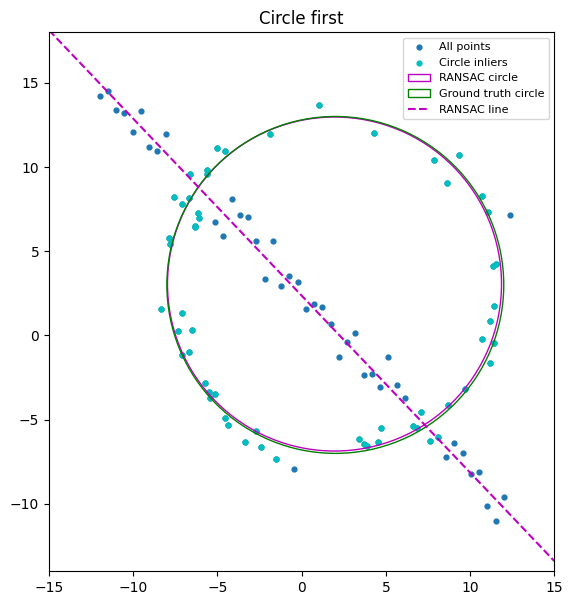

In [8]:
circ_first = ransac(X, 3, circle_from_points, circle_error, fit_circle, t_circ, min_circ, n_iter=3000, seed=3)
mask2 = np.ones(len(X), bool); mask2[circ_first['inliers']] = False
X_rem2 = X[mask2]
line_second = ransac(X_rem2, 2, line_from_points, line_error, fit_line, t_line, 20)
print('Circle first  ->', np.round(circ_first['model'], 3), ' inliers:', len(circ_first['inliers']))
print('Line second   ->', np.round(line_second['model'], 3), ' inliers:', len(line_second['inliers']))

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], s=12, label='All points')
ax.scatter(X[circ_first['inliers'], 0], X[circ_first['inliers'], 1], s=12, color='c', label='Circle inliers')
cm = circ_first['model']
ax.add_patch(plt.Circle(cm[:2], cm[2], color='m', fill=False, label='RANSAC circle'))
ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
plot_line(ax, line_second['model'], (-15, 15), color='m', ls='--', label='RANSAC line')
ax.set_xlim(-15, 15); ax.set_ylim(-14, 18); ax.set_aspect('equal'); ax.legend(fontsize=8)
ax.set_title('Circle first'); plt.show()

**Answer (d): what happens if we fit the circle first?**

Fitting the circle first gives a worse result, because a circle can imitate a line but a line cannot imitate a circle.

- **Degenerate circle.** Three nearly collinear line points give a circle with a very large radius. Over the data range (−12 to 12) its arc is almost straight, so it can collect all 50 line points plus a few circle points. That can beat the true circle's consensus, and RANSAC returns the "line" as the circle.
- **Stolen points.** Even when the correct circle wins, line points near the two places where the line crosses the circle fall inside the radial band. In our run the circle took 57 inliers instead of about 50, so 7 or more of them were line points. These bias the circle fit and are removed before the line is fitted, so the line gets fewer points (39 instead of 48).

Fitting the line first avoids both problems: the line has fewer parameters, its 2-point sample cannot explain the circle points, and only a few circle points sit near the line. If the circle must come first, limit the radius (reject samples with $r > r_{max}$) and require a minimum consensus.

### Question 03

In [9]:
def get_four_points(img, win='Click TL, TR, BR, BL  (Esc to cancel)'):
    pts, disp = [], img.copy()
    def cb(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < 4:
            pts.append([x, y])
            cv.circle(disp, (x, y), 6, (0, 0, 255), -1)
            cv.imshow(win, disp)
    cv.namedWindow(win, cv.WINDOW_NORMAL)
    cv.imshow(win, disp)
    cv.setMouseCallback(win, cb)
    while len(pts) < 4:
        if cv.waitKey(20) & 0xFF == 27:
            break
    cv.waitKey(300); cv.destroyWindow(win); cv.waitKey(1)
    return np.array(pts, dtype=np.float32)

def superimpose(base, overlay, dst_pts, alpha=0.6):
    ho, wo = overlay.shape[:2]
    hb, wb = base.shape[:2]
    src = np.float32([[0, 0], [wo - 1, 0], [wo - 1, ho - 1], [0, ho - 1]])
    H = cv.getPerspectiveTransform(src, np.float32(dst_pts))
    warped = cv.warpPerspective(overlay, H, (wb, hb))
    m = cv.warpPerspective(np.ones((ho, wo), np.float32), H, (wb, hb))[..., None]
    out = base.astype(np.float32) * (1 - alpha * m) + warped.astype(np.float32) * alpha * m
    return np.clip(out, 0, 255).astype(np.uint8), H

images/arch/001.jpg points = [[445.0, 114.0], [726.0, 58.0], [726.0, 256.0], [445.0, 255.0]]
H =
 [[ 1.88e-02  0.00e+00  4.45e+02]
 [-1.89e-02  6.53e-02  1.14e+02]
 [-1.00e-04  0.00e+00  1.00e+00]]


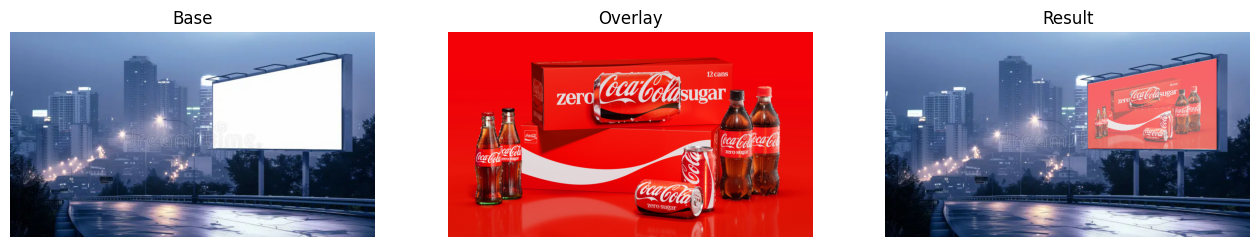

images/arch/002.jpg points = [[77.0, 76.0], [300.0, 126.0], [301.0, 281.0], [70.0, 310.0]]
H =
 [[ 2.116e-01 -1.080e-02  7.700e+01]
 [ 6.410e-02  2.501e-01  7.600e+01]
 [ 3.000e-04 -0.000e+00  1.000e+00]]


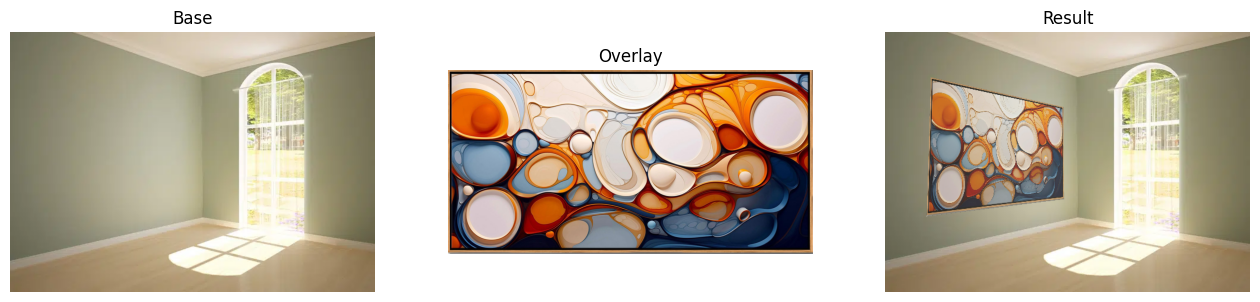

In [14]:
pairs = [
    dict(base='images/arch/001.jpg', overlay='images/overlay/cola.png', pts=None, alpha=0.6),
    dict(base='images/arch/002.jpg', overlay='images/overlay/paint.png', pts=None, alpha=0.7),
]

for p in pairs:
    base, overlay = cv.imread(p['base']), cv.imread(p['overlay'])
    if base is None or overlay is None:
        print('Skipping (image not found):', p['base'], p['overlay']); continue
    pts = get_four_points(base) if p['pts'] is None else np.float32(p['pts'])
    if len(pts) != 4:
        print('Need exactly 4 points'); continue
    print(p['base'], 'points =', pts.tolist())
    result, H = superimpose(base, overlay, pts, p['alpha'])
    print('H =\n', np.round(H, 4))
    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    for a, img, ttl in zip(ax, [base, overlay, result], ['Base', 'Overlay', 'Result']):
        a.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); a.set_title(ttl); a.axis('off')
    plt.show()

**Explanation (Q3).** The four corners of the overlay are mapped to the four clicked points by a 3×3 homography $H$ (8 degrees of freedom, so exactly 4 point pairs fix it). The overlay is warped into the base image frame with $H$, a warped mask marks where it lands, and inside that mask the two images are blended with weight α.

- **Why it works.** A homography maps one plane to another exactly, so the overlay looks painted on the wall only if all four points lie on one planar surface.
- **Choice of α.** About 0.6 keeps the wall texture (windows, bricks) visible through the overlay, which makes it look real.

**Rationale for my image pairs.**

- **Advertisement on a city billboard.** Before paying to print and rent a billboard, an advertiser wants to see how the campaign will look in its real setting: whether it stands out against the night skyline, and whether the product and logo are still readable from the road. Superimposing the Coca-Cola ad on a blank billboard gives that preview without printing anything.
- **Painting on a room wall.** When buying art online or planning an interior, people want to see whether a painting suits the room's size, colours and light before buying. Placing the abstract painting on the side wall of an empty room shows how its warm orange and blue tones look against the green wall and the daylight from the window.

Both scenes suit a homography: the billboard face and the wall are flat, have clear corners to click, and are seen at an angle, so the perspective warp is clearly visible (the painting narrows towards the room corner).